# tasks W-02

In [2]:
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None 
import pickle

import os
from importlib import reload

import matplotlib.pyplot as plt
import matplotlib 
# import seaborn as sns
%matplotlib inline
plt.style.use('ggplot')
from matplotlib.ticker import MultipleLocator

### load data

In [30]:
df_comp_details = pd.read_csv('duopoly_competition_details_bad.csv')
df_comp_details.fillna(0, inplace=True)
df_comp_details.head(3)

,competition_id,selling_season,selling_period,competitor_id,price_competitor,price,demand,competitor_has_capacity,calculation_duration,errors
0,339UBs,1,1,HospitableBeaver,50.0,65.0,0,True,0.0,0.0
1,339UBs,1,2,HospitableBeaver,1.0,65.0,0,True,0.0,0.0
2,339UBs,1,3,HospitableBeaver,1.0,65.0,0,True,0.0,0.0


## (1) find based on your own competition details CSV the best (max revenue) capacity utilization curve

### (a) compute the revenue for all selling_seasons and competitions

In [31]:
df_comp_details['revenue'] =   df_comp_details['demand']*df_comp_details['price']
df_comp_details.tail(5)

,competition_id,selling_season,selling_period,competitor_id,price_competitor,price,demand,competitor_has_capacity,calculation_duration,errors,revenue
39995,8GTkrF,100,96,UnbiasedCurassow,29.5,30.0,0,True,0.0,0.0,0.0
39996,8GTkrF,100,97,UnbiasedCurassow,18.5,30.0,0,True,0.0,0.0,0.0
39997,8GTkrF,100,98,UnbiasedCurassow,29.5,30.0,0,True,0.0,0.0,0.0
39998,8GTkrF,100,99,UnbiasedCurassow,29.5,30.0,0,True,0.0,0.0,0.0
39999,8GTkrF,100,100,UnbiasedCurassow,29.5,30.0,0,True,0.0,0.0,0.0


In [32]:
df_comp_details['unique_selling_season_key'] =  df_comp_details.apply(
    lambda r: f"{r.competition_id}_{r.selling_season}", axis=1
) 
df_comp_details.head(2)

,competition_id,selling_season,selling_period,competitor_id,price_competitor,price,demand,competitor_has_capacity,calculation_duration,errors,revenue,unique_selling_season_key
0,339UBs,1,1,HospitableBeaver,50.0,65.0,0,True,0.0,0.0,0.0,339UBs_1
1,339UBs,1,2,HospitableBeaver,1.0,65.0,0,True,0.0,0.0,0.0,339UBs_1


In [33]:
dfx_rev = df_comp_details.groupby('unique_selling_season_key').agg({
    'revenue' : 'sum'
}).reset_index()
dfx_rev

,unique_selling_season_key,revenue
0,339UBs_1,0.0
1,339UBs_10,30.0
2,339UBs_100,90.0
3,339UBs_11,30.0
4,339UBs_12,60.0
...,...,...
395,8GTkrF_95,0.0
396,8GTkrF_96,0.0
397,8GTkrF_97,0.0
398,8GTkrF_98,0.0


array([[<Axes: title={'center': 'revenue'}>]], dtype=object)

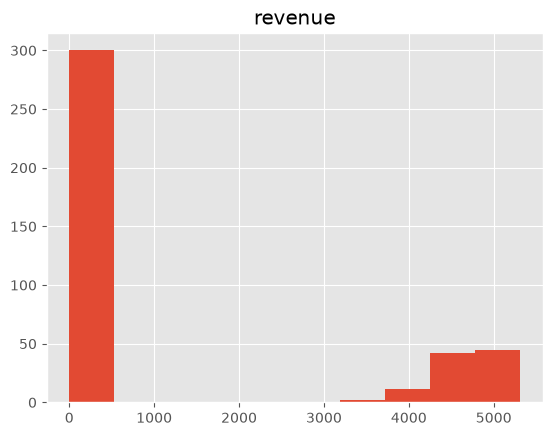

In [34]:
dfx_rev.hist()

In [35]:
dfx_rev.describe()

,revenue
count,400.000000
mean,1174.350500
std,2026.989365
min,0.000000
25%,0.000000
50%,0.000000
75%,943.200000
max,5311.600000


### get the selling season keys with the top 20% revenue generation

In [36]:
dfx_rev.revenue.quantile(0.8)

np.float64(4369.76)

In [37]:
top_selling_seasons = dfx_rev[dfx_rev['revenue'] >= dfx_rev['revenue'].quantile(0.8)].unique_selling_season_key.unique()
top_selling_seasons[:10]

<StringArray>
[ '4EWNCR_10', '4EWNCR_100',  '4EWNCR_12',  '4EWNCR_14',  '4EWNCR_17',
  '4EWNCR_18',  '4EWNCR_19',   '4EWNCR_2',  '4EWNCR_20',  '4EWNCR_21']
Length: 10, dtype: str

In [38]:
# quick double check
dfx_rev[dfx_rev.unique_selling_season_key.isin(top_selling_seasons)].revenue.mean()

np.float64(4807.29)

### (b) compute the capacity utilization curves per selling season

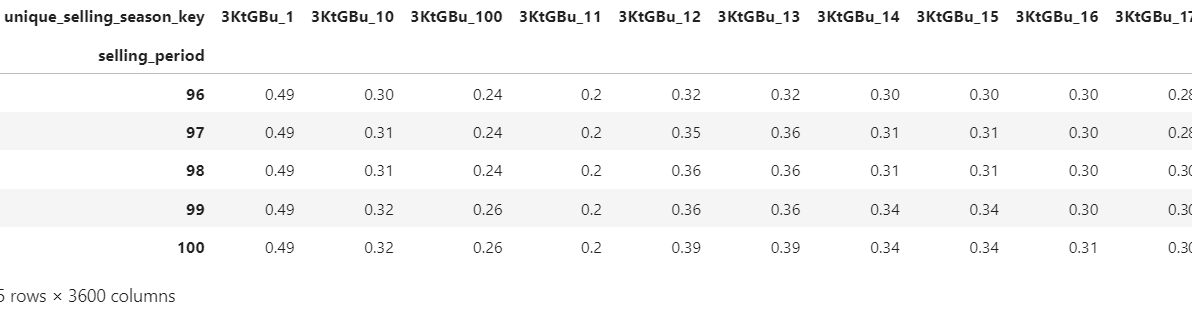

In [39]:
dfp_util = pd.pivot_table(df_comp_details, 
                        values='demand', 
                        index=['selling_period'],
                        columns=['unique_selling_season_key'], 
                        aggfunc="mean")

dfp_util.tail()

unique_selling_season_key,339UBs_1,339UBs_10,339UBs_100,339UBs_11,339UBs_12,339UBs_13,339UBs_14,339UBs_15,339UBs_16,339UBs_17,...,8GTkrF_90,8GTkrF_91,8GTkrF_92,8GTkrF_93,8GTkrF_94,8GTkrF_95,8GTkrF_96,8GTkrF_97,8GTkrF_98,8GTkrF_99
selling_period,,,,,,,,,,,,,,,,,,,,,
96,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
97,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
98,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
99,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### compute the utilization fractions

In [40]:
for c in dfp_util.columns:
    dfp_util[c] = dfp_util[c].cumsum()
    dfp_util[c] = round(dfp_util[c] / 80, 2)
    
dfp_util.tail()

unique_selling_season_key,339UBs_1,339UBs_10,339UBs_100,339UBs_11,339UBs_12,339UBs_13,339UBs_14,339UBs_15,339UBs_16,339UBs_17,...,8GTkrF_90,8GTkrF_91,8GTkrF_92,8GTkrF_93,8GTkrF_94,8GTkrF_95,8GTkrF_96,8GTkrF_97,8GTkrF_98,8GTkrF_99
selling_period,,,,,,,,,,,,,,,,,,,,,
96,0.0,0.01,0.04,0.01,0.02,0.0,0.01,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
97,0.0,0.01,0.04,0.01,0.02,0.0,0.01,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
98,0.0,0.01,0.04,0.01,0.02,0.0,0.01,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
99,0.0,0.01,0.04,0.01,0.02,0.0,0.01,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100,0.0,0.01,0.04,0.01,0.02,0.0,0.01,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


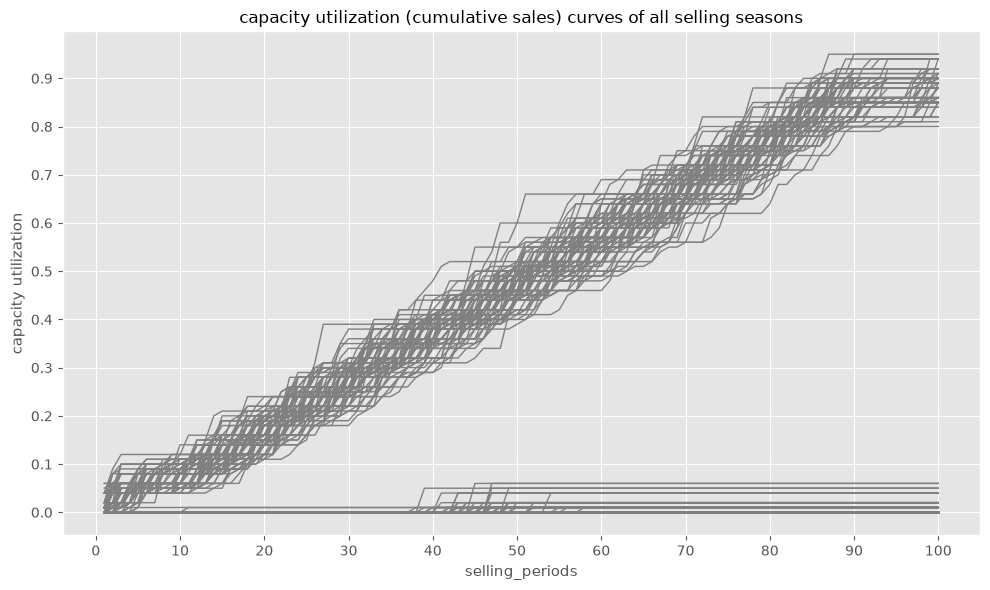

In [41]:
fig, ax = plt.subplots(figsize=(10,6))

ax.plot(dfp_util.index, dfp_util, color='grey', 
        linestyle='-', linewidth=1, )
ax.set_xlabel('selling_periods', size=11)
# ax.set_xticks(np.arange(min(dft.index), max(dft.index)+1, 1.0))
ax.set_ylabel("capacity utilization" , size=11)

y_majorLocator = MultipleLocator(0.1)
ax.yaxis.set_major_locator(y_majorLocator)
x_majorLocator = MultipleLocator(10)
ax.xaxis.set_major_locator(x_majorLocator)

ax.set_title("capacity utilization (cumulative sales) curves of all selling seasons", size=12)
# ax.legend(loc=0)

ax.grid(True)
fig.tight_layout()

plt.show()

### show only the top revenue curves

In [42]:
dfp_top_curves = dfp_util[top_selling_seasons].copy()
dfp_top_curves.shape

(100, 80)

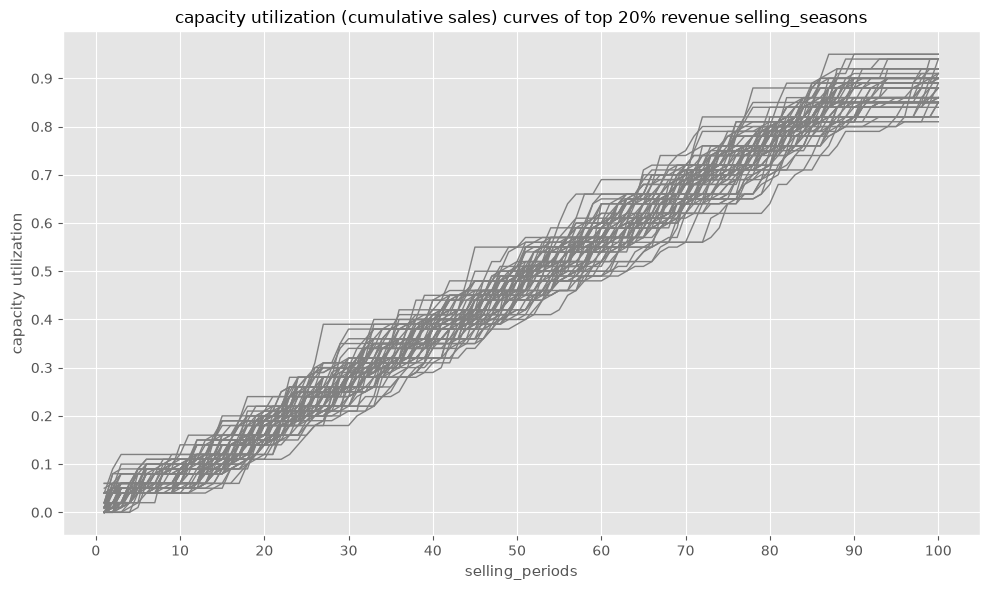

In [43]:
fig, ax = plt.subplots(figsize=(10,6))

ax.plot(dfp_top_curves.index, dfp_top_curves, color='grey', 
        linestyle='-', linewidth=1, )
ax.set_xlabel('selling_periods', size=11)
# ax.set_xticks(np.arange(min(dft.index), max(dft.index)+1, 1.0))
ax.set_ylabel("capacity utilization" , size=11)

y_majorLocator = MultipleLocator(0.1)
ax.yaxis.set_major_locator(y_majorLocator)
x_majorLocator = MultipleLocator(10)
ax.xaxis.set_major_locator(x_majorLocator)

ax.set_title("capacity utilization (cumulative sales) curves of top 20% revenue selling_seasons", size=12)
# ax.legend(loc=0)

ax.grid(True)
fig.tight_layout()

plt.show()

#### get the mean curve of the top revenue generating ones

<Axes: xlabel='selling_period'>

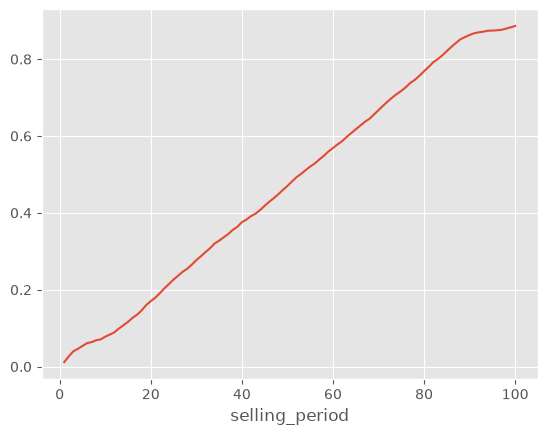

In [45]:
dfp_top_curves['mean_curve'] = dfp_top_curves.mean(axis=1)
dfp_top_curves['mean_curve'].plot()

In [20]:
dfp_top_curves

unique_selling_season_key,3RCuyb_26,3RCuyb_36,3RCuyb_38,3RCuyb_85,3RCuyb_98,3erHqy_100,3erHqy_11,3erHqy_12,3erHqy_14,3erHqy_16,...,45cC4i_96,45cC4i_97,45cC4i_98,45cC4i_99,VgXDDB_18,VgXDDB_19,VgXDDB_3,VgXDDB_48,VgXDDB_67,mean_curve
selling_period,,,,,,,,,,,,,,,,,,,,,
1,0.01,0.00,0.00,0.00,0.00,0.02,0.02,0.00,0.00,0.04,...,0.01,0.02,0.00,0.00,0.02,0.01,0.00,0.04,0.00,0.010500
2,0.02,0.01,0.00,0.01,0.00,0.02,0.02,0.00,0.01,0.04,...,0.01,0.02,0.00,0.00,0.02,0.01,0.01,0.04,0.00,0.018417
3,0.02,0.01,0.01,0.02,0.00,0.02,0.02,0.01,0.01,0.04,...,0.01,0.04,0.02,0.04,0.05,0.01,0.04,0.05,0.02,0.028000
4,0.02,0.05,0.05,0.04,0.02,0.02,0.02,0.02,0.04,0.04,...,0.02,0.04,0.05,0.04,0.05,0.05,0.04,0.05,0.02,0.035500
5,0.02,0.06,0.05,0.04,0.04,0.02,0.02,0.02,0.04,0.04,...,0.02,0.04,0.05,0.04,0.05,0.05,0.04,0.05,0.02,0.039750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,0.86,0.90,0.92,0.94,0.92,0.95,0.90,0.89,0.90,0.84,...,0.88,0.84,0.90,0.84,0.88,0.86,0.88,0.91,0.86,0.845917
97,0.86,0.90,0.92,0.94,0.92,0.95,0.90,0.89,0.90,0.84,...,0.88,0.84,0.90,0.84,0.88,0.86,0.88,0.91,0.86,0.846750
98,0.86,0.90,0.92,0.94,0.92,0.95,0.90,0.89,0.90,0.84,...,0.88,0.84,0.90,0.84,0.88,0.86,0.88,0.91,0.86,0.847833


#### generate dict to describe the cruve at every 5th selling period in the selling season

In [21]:
target_sales_curve = {}
for t in np.arange(1,101,5):
    target = {}
    target['cap_util'] = round(dfp_top_curves.loc[t,'mean_curve'],2)
    target['sold_seats'] = round(dfp_top_curves.loc[t,'mean_curve'] * 80)
    target_sales_curve[t] = target
    
target_sales_curve

{np.int64(1): {'cap_util': np.float64(0.01), 'sold_seats': 1},
 np.int64(6): {'cap_util': np.float64(0.05), 'sold_seats': 4},
 np.int64(11): {'cap_util': np.float64(0.08), 'sold_seats': 6},
 np.int64(16): {'cap_util': np.float64(0.12), 'sold_seats': 10},
 np.int64(21): {'cap_util': np.float64(0.17), 'sold_seats': 13},
 np.int64(26): {'cap_util': np.float64(0.21), 'sold_seats': 17},
 np.int64(31): {'cap_util': np.float64(0.27), 'sold_seats': 21},
 np.int64(36): {'cap_util': np.float64(0.32), 'sold_seats': 25},
 np.int64(41): {'cap_util': np.float64(0.36), 'sold_seats': 29},
 np.int64(46): {'cap_util': np.float64(0.41), 'sold_seats': 33},
 np.int64(51): {'cap_util': np.float64(0.45), 'sold_seats': 36},
 np.int64(56): {'cap_util': np.float64(0.49), 'sold_seats': 40},
 np.int64(61): {'cap_util': np.float64(0.54), 'sold_seats': 43},
 np.int64(66): {'cap_util': np.float64(0.59), 'sold_seats': 47},
 np.int64(71): {'cap_util': np.float64(0.64), 'sold_seats': 51},
 np.int64(76): {'cap_util': np

In [22]:
with open('target_sales_curve.pkl', "wb") as f:
    pickle.dump(target_sales_curve, f, protocol=pickle.HIGHEST_PROTOCOL)

## (2) implement the logic to follow this capacity utilization curve by controlling the price to stay close to the curve 

## price up -> slow down sales 
## price down -> increase sales

#### prepare given demand input for given competition and given selling season

In [23]:
with open('target_sales_curve.pkl', 'rb') as f:
            target_curve = pickle.load(f)
target_curve

{np.int64(1): {'cap_util': np.float64(0.01), 'sold_seats': 1},
 np.int64(6): {'cap_util': np.float64(0.05), 'sold_seats': 4},
 np.int64(11): {'cap_util': np.float64(0.08), 'sold_seats': 6},
 np.int64(16): {'cap_util': np.float64(0.12), 'sold_seats': 10},
 np.int64(21): {'cap_util': np.float64(0.17), 'sold_seats': 13},
 np.int64(26): {'cap_util': np.float64(0.21), 'sold_seats': 17},
 np.int64(31): {'cap_util': np.float64(0.27), 'sold_seats': 21},
 np.int64(36): {'cap_util': np.float64(0.32), 'sold_seats': 25},
 np.int64(41): {'cap_util': np.float64(0.36), 'sold_seats': 29},
 np.int64(46): {'cap_util': np.float64(0.41), 'sold_seats': 33},
 np.int64(51): {'cap_util': np.float64(0.45), 'sold_seats': 36},
 np.int64(56): {'cap_util': np.float64(0.49), 'sold_seats': 40},
 np.int64(61): {'cap_util': np.float64(0.54), 'sold_seats': 43},
 np.int64(66): {'cap_util': np.float64(0.59), 'sold_seats': 47},
 np.int64(71): {'cap_util': np.float64(0.64), 'sold_seats': 51},
 np.int64(76): {'cap_util': np

In [24]:
id = df_comp_details['unique_selling_season_key'].unique()[10]
df_select = df_comp_details[df_comp_details.unique_selling_season_key==id]

selling_period_in_current_season = 31

In [25]:
demand_historical_in_current_season  = np.array(
            df_select[df_select.selling_period < selling_period_in_current_season]['demand']
)
demand_historical_in_current_season

array([0, 0, 0, 0, 2, 1, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 2, 0, 0, 1, 1, 1])

In [26]:
prices_historical_in_current_season = [ 
    df_select[df_select.selling_period < selling_period_in_current_season]['price'], 
    df_select[df_select.selling_period < selling_period_in_current_season]['price_competitor'] ]
prices_historical_in_current_season  = np.array(prices_historical_in_current_season)

prices_historical_in_current_season

array([[ 65. ,  65. ,  65. ,  41.2,  41.2,  41.2,  57.4,  57.4,  57.4,
         55.7,  55.7,  55.7,  51.1,  51.1,  51.1,  56.7,  56.7,  56.7,
         55.5,  55.5,  55.5,  55.1,  55.1,  55.1,  52.9,  52.9,  52.9,
         54.2,  54.2,  54.2],
       [100. , 100. , 100. , 100. , 100. , 100. , 100. , 100. , 100. ,
        100. , 100. , 100. , 100. , 100. , 100. , 100. , 100. , 100. ,
        100. , 100. , 100. , 100. , 100. , 100. , 100. , 100. , 100. ,
        100. , 100. , 100. ]])

### logic

In [27]:
last_price = prices_historical_in_current_season[0][-1]
last_price

np.float64(54.2)

In [28]:
current_sold_seats = demand_historical_in_current_season.sum()
current_sold_seats

np.int64(12)

In [29]:
print("old price: %.2f" % last_price)

if selling_period_in_current_season in target_curve.keys():
    
    target = target_curve[selling_period_in_current_season]
    target_sales = target['sold_seats']
    
    print("sold seats: %d " % current_sold_seats)
    print("target sold seats: %d " % target_sales)
    
    delta_in_sales =  (current_sold_seats - target_sales) / target_sales
    print("percentage delta to target: %.2f" % delta_in_sales)
    
    ###
    # adjust price according to the delta
    price =  last_price * (1 + delta_in_sales)
    price=min(price,110)
    price=max(price,20)
    print("new price: %.2f" % price)


old price: 54.20
sold seats: 12 
target sold seats: 21 
percentage delta to target: -0.43
new price: 30.97
